# k-NN V7

For this experiment, I wanted to check if the training sizes I selected in V6 still worked best with more validation samples. I tested the same four sizes again, but this time I used the full validation set for each dataset.

First, I imported the libraries and functions I'll need.

In [1]:
from pathlib import Path
from time import perf_counter
import sys

import pandas as pd
import matplotlib.pyplot as plt

project_root = Path.cwd()
if not (project_root / "src").is_dir():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

from src.data_loader import load_task, split_train_val
from src.models.knn import KNNClassifier, euclidean_distance

image_k = 1
sentiment_k = 3
training_sizes = [1000, 2000, 4000, 8000]


I started by testing the training sizes with all the image validation samples.

In [2]:
X, y, image_X_test, image_test_ids = load_task("image")
image_X_train, image_X_val, image_y_train, image_y_val = split_train_val(
    X, y, val_fraction=0.2, seed=42
)
assert len(image_X_val) == 4000
assert len(image_X_train) >= max(training_sizes)

result_dir = project_root / "results" / "image"
image_v6_summary = pd.read_csv(result_dir / "knn_v6_summary.csv")
v6_validation = pd.read_csv(result_dir / "knn_v6_validation.csv")
image_v6_best = image_v6_summary.sort_values(
    ["validation_accuracy", "training_samples"], ascending=[False, True]
).iloc[0]
image_v6_best_size = int(image_v6_best["training_samples"])
assert v6_validation["validation_index"].tolist() == list(range(200))
assert v6_validation["actual_label"].tolist() == image_y_val[:200].tolist()

image_rows = []
image_validation_predictions = {}
image_best_accuracy = -1
print("Image: k=" + str(image_k) + ", 4000 validation samples")
for training_size in training_sizes:
    train_features = image_X_train[:training_size]
    train_labels = image_y_train[:training_size]
    clf = KNNClassifier(k=image_k, distance_fn=euclidean_distance, voting_method="majority")
    clf.fit(train_features, train_labels)
    start = perf_counter()
    y_pred = clf.predict(image_X_val)
    prediction_time = perf_counter() - start
    accuracy = sum(p == t for p, t in zip(y_pred, image_y_val)) / len(image_y_val)
    image_validation_predictions[training_size] = y_pred

    first_200_accuracy = sum(p == t for p, t in zip(y_pred[:200], image_y_val[:200])) / 200
    v6_accuracy = image_v6_summary.loc[
        image_v6_summary["training_samples"] == training_size, "validation_accuracy"
    ].iloc[0]
    assert first_200_accuracy == v6_accuracy
    if training_size == image_v6_best_size:
        assert y_pred[:200] == v6_validation["predicted_label"].tolist()

    image_rows.append({
        "dataset": "image",
        "version": "V7",
        "k": image_k,
        "distance_metric": "euclidean",
        "voting_method": "majority",
        "normalized": False,
        "training_samples": len(train_features),
        "validation_samples": len(image_X_val),
        "validation_accuracy": accuracy,
        "prediction_time_seconds": prediction_time,
    })
    print(f"Training samples={training_size:4d}  full accuracy={accuracy:.4%}  prediction time={prediction_time:.6f} s")
    print(f"First 200 accuracy={first_200_accuracy:.2%}; V6 check passed.")

    # Sizes are ascending, so the smaller size wins an accuracy tie.
    if accuracy > image_best_accuracy:
        image_best_size = training_size
        image_best_accuracy = accuracy

image_summary = pd.DataFrame(image_rows)
image_summary.to_csv(result_dir / "knn_v7_summary.csv", index=False)
pd.DataFrame({
    "validation_index": range(len(image_y_val)),
    "actual_label": image_y_val,
    "predicted_label": image_validation_predictions[image_best_size],
}).to_csv(result_dir / "knn_v7_validation.csv", index=False)
print(f"Selected training size: {image_best_size}, full accuracy={image_best_accuracy:.4%}")


Image: k=1, 4000 validation samples
Training samples=1000  full accuracy=17.9000%  prediction time=10.271287 s
First 200 accuracy=21.50%; V6 check passed.
Training samples=2000  full accuracy=23.8000%  prediction time=26.220567 s
First 200 accuracy=26.50%; V6 check passed.
Training samples=4000  full accuracy=31.0750%  prediction time=87.239307 s
First 200 accuracy=34.00%; V6 check passed.
Training samples=8000  full accuracy=39.6250%  prediction time=158.668253 s
First 200 accuracy=45.50%; V6 check passed.
Selected training size: 8000, full accuracy=39.6250%


Then I repeated the same test with the sentiment dataset.

In [3]:
X, y, sentiment_X_test, sentiment_test_ids = load_task("sentiment")
sentiment_X_train, sentiment_X_val, sentiment_y_train, sentiment_y_val = split_train_val(
    X, y, val_fraction=0.2, seed=42
)
assert len(sentiment_X_val) == 2400
assert len(sentiment_X_train) >= max(training_sizes)

result_dir = project_root / "results" / "sentiment"
sentiment_v6_summary = pd.read_csv(result_dir / "knn_v6_summary.csv")
v6_validation = pd.read_csv(result_dir / "knn_v6_validation.csv")
sentiment_v6_best = sentiment_v6_summary.sort_values(
    ["validation_accuracy", "training_samples"], ascending=[False, True]
).iloc[0]
sentiment_v6_best_size = int(sentiment_v6_best["training_samples"])
assert v6_validation["validation_index"].tolist() == list(range(200))
assert v6_validation["actual_label"].tolist() == sentiment_y_val[:200].tolist()

sentiment_rows = []
sentiment_validation_predictions = {}
sentiment_best_accuracy = -1
print("Sentiment: k=" + str(sentiment_k) + ", 2400 validation samples")
for training_size in training_sizes:
    train_features = sentiment_X_train[:training_size]
    train_labels = sentiment_y_train[:training_size]
    clf = KNNClassifier(k=sentiment_k, distance_fn=euclidean_distance, voting_method="majority")
    clf.fit(train_features, train_labels)
    start = perf_counter()
    y_pred = clf.predict(sentiment_X_val)
    prediction_time = perf_counter() - start
    accuracy = sum(p == t for p, t in zip(y_pred, sentiment_y_val)) / len(sentiment_y_val)
    sentiment_validation_predictions[training_size] = y_pred

    first_200_accuracy = sum(p == t for p, t in zip(y_pred[:200], sentiment_y_val[:200])) / 200
    v6_accuracy = sentiment_v6_summary.loc[
        sentiment_v6_summary["training_samples"] == training_size, "validation_accuracy"
    ].iloc[0]
    assert first_200_accuracy == v6_accuracy
    if training_size == sentiment_v6_best_size:
        assert y_pred[:200] == v6_validation["predicted_label"].tolist()

    sentiment_rows.append({
        "dataset": "sentiment",
        "version": "V7",
        "k": sentiment_k,
        "distance_metric": "euclidean",
        "voting_method": "majority",
        "normalized": False,
        "training_samples": len(train_features),
        "validation_samples": len(sentiment_X_val),
        "validation_accuracy": accuracy,
        "prediction_time_seconds": prediction_time,
    })
    print(f"Training samples={training_size:4d}  full accuracy={accuracy:.4%}  prediction time={prediction_time:.6f} s")
    print(f"First 200 accuracy={first_200_accuracy:.2%}; V6 check passed.")

    # Sizes are ascending, so the smaller size wins an accuracy tie.
    if accuracy > sentiment_best_accuracy:
        sentiment_best_size = training_size
        sentiment_best_accuracy = accuracy

sentiment_summary = pd.DataFrame(sentiment_rows)
sentiment_summary.to_csv(result_dir / "knn_v7_summary.csv", index=False)
pd.DataFrame({
    "validation_index": range(len(sentiment_y_val)),
    "actual_label": sentiment_y_val,
    "predicted_label": sentiment_validation_predictions[sentiment_best_size],
}).to_csv(result_dir / "knn_v7_validation.csv", index=False)
print(f"Selected training size: {sentiment_best_size}, full accuracy={sentiment_best_accuracy:.4%}")


Sentiment: k=3, 2400 validation samples
Training samples=1000  full accuracy=47.7500%  prediction time=9.641827 s
First 200 accuracy=57.50%; V6 check passed.
Training samples=2000  full accuracy=48.6250%  prediction time=27.032414 s
First 200 accuracy=48.50%; V6 check passed.
Training samples=4000  full accuracy=50.5000%  prediction time=64.812463 s
First 200 accuracy=52.50%; V6 check passed.
Training samples=8000  full accuracy=50.6667%  prediction time=117.257747 s
First 200 accuracy=55.50%; V6 check passed.
Selected training size: 8000, full accuracy=50.6667%


I plotted the results to compare them with V6.

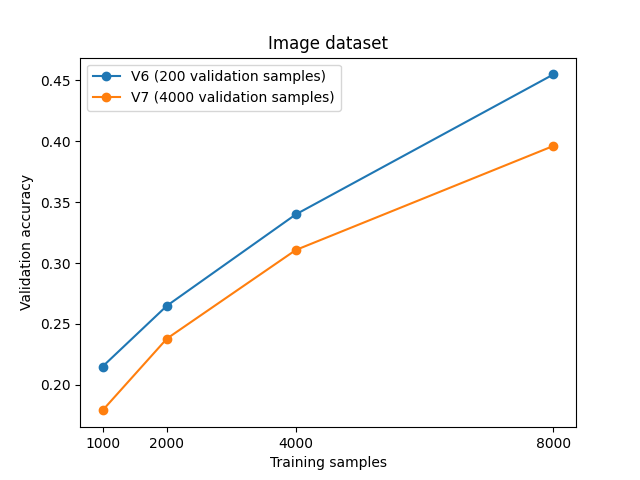

In [4]:
knn_result_dir = project_root / "results" / "knn"
knn_result_dir.mkdir(parents=True, exist_ok=True)
plt.figure()
plt.plot(image_v6_summary["training_samples"], image_v6_summary["validation_accuracy"], marker="o", label="V6 (200 validation samples)")
plt.plot(image_summary["training_samples"], image_summary["validation_accuracy"], marker="o", label="V7 (4000 validation samples)")
plt.xlabel("Training samples")
plt.ylabel("Validation accuracy")
plt.title("Image dataset")
plt.xticks(training_sizes)
plt.legend()
plt.savefig(knn_result_dir / "knn_v7_image_accuracy.png")
plt.show()


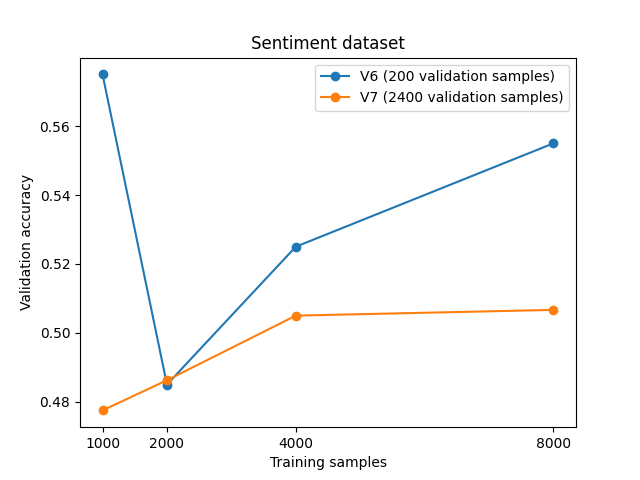

In [5]:
knn_result_dir = project_root / "results" / "knn"
knn_result_dir.mkdir(parents=True, exist_ok=True)
plt.figure()
plt.plot(sentiment_v6_summary["training_samples"], sentiment_v6_summary["validation_accuracy"], marker="o", label="V6 (200 validation samples)")
plt.plot(sentiment_summary["training_samples"], sentiment_summary["validation_accuracy"], marker="o", label="V7 (2400 validation samples)")
plt.xlabel("Training samples")
plt.ylabel("Validation accuracy")
plt.title("Sentiment dataset")
plt.xticks(training_sizes)
plt.legend()
plt.savefig(knn_result_dir / "knn_v7_sentiment_accuracy.png")
plt.show()


Finally, I compared the accuracies to choose the best training size for each dataset.

In [6]:
for dataset, previous, current, previous_size, selected_size in [
    ("Image", image_v6_summary, image_summary, image_v6_best_size, image_best_size),
    ("Sentiment", sentiment_v6_summary, sentiment_summary, sentiment_v6_best_size, sentiment_best_size),
]:
    comparison = previous[["training_samples", "validation_accuracy"]].merge(
        current[["training_samples", "validation_accuracy"]], on="training_samples", suffixes=("_v6", "_v7")
    )
    print(dataset)
    print(comparison.to_string(index=False))
    print(f"V6 best size: {previous_size}; V7 best size: {selected_size}")
    print(f"Selected size changed: {previous_size != selected_size}")


Image
 training_samples  validation_accuracy_v6  validation_accuracy_v7
             1000                   0.215                 0.17900
             2000                   0.265                 0.23800
             4000                   0.340                 0.31075
             8000                   0.455                 0.39625
V6 best size: 8000; V7 best size: 8000
Selected size changed: False
Sentiment
 training_samples  validation_accuracy_v6  validation_accuracy_v7
             1000                   0.575                0.477500
             2000                   0.485                0.486250
             4000                   0.525                0.505000
             8000                   0.555                0.506667
V6 best size: 1000; V7 best size: 8000
Selected size changed: True


I used the selected training sizes to predict the test labels.

In [7]:
assert image_v6_best["k"] == image_k
assert image_v6_best["distance_metric"] == "euclidean"
assert image_v6_best["voting_method"] == "majority"
assert not image_v6_best["normalized"]
if image_best_size == image_v6_best_size:
    v6_submission = pd.read_csv(project_root / "submission" / "knn" / "submission_v6_knn.csv")
    assert v6_submission.columns.tolist() == ["id", "label"]
    assert len(v6_submission) == 10000 and v6_submission["id"].is_unique
    previous_predictions = pd.DataFrame({"id": image_test_ids}).merge(
        v6_submission, on="id", how="left", sort=False
    )
    assert not previous_predictions.isna().any().any()
    image_test_predictions = previous_predictions["label"].tolist()
    print("Reused V6 image predictions: the selected training size and model settings are identical.")
else:
    image_clf = KNNClassifier(
        k=image_k, distance_fn=euclidean_distance, voting_method="majority"
    )
    image_clf.fit(image_X_train[:image_best_size], image_y_train[:image_best_size])
    start = perf_counter()
    image_test_predictions = image_clf.predict(image_X_test)
    print(f"Image: predicted {len(image_test_predictions)} test labels in {perf_counter() - start:.2f} s")


Reused V6 image predictions: the selected training size and model settings are identical.


In [8]:
assert sentiment_v6_best["k"] == sentiment_k
assert sentiment_v6_best["distance_metric"] == "euclidean"
assert sentiment_v6_best["voting_method"] == "majority"
assert not sentiment_v6_best["normalized"]
if sentiment_best_size == sentiment_v6_best_size:
    v6_submission = pd.read_csv(project_root / "submission" / "knn" / "submission_v6_knn.csv")
    assert v6_submission.columns.tolist() == ["id", "label"]
    assert len(v6_submission) == 10000 and v6_submission["id"].is_unique
    previous_predictions = pd.DataFrame({"id": sentiment_test_ids}).merge(
        v6_submission, on="id", how="left", sort=False
    )
    assert not previous_predictions.isna().any().any()
    sentiment_test_predictions = previous_predictions["label"].tolist()
    print("Reused V6 sentiment predictions: the selected training size and model settings are identical.")
else:
    sentiment_clf = KNNClassifier(
        k=sentiment_k, distance_fn=euclidean_distance, voting_method="majority"
    )
    sentiment_clf.fit(sentiment_X_train[:sentiment_best_size], sentiment_y_train[:sentiment_best_size])
    start = perf_counter()
    sentiment_test_predictions = sentiment_clf.predict(sentiment_X_test)
    print(f"Sentiment: predicted {len(sentiment_test_predictions)} test labels in {perf_counter() - start:.2f} s")


Sentiment: predicted 5000 test labels in 253.94 s


In [9]:
image_predictions = pd.DataFrame({"id": image_test_ids, "label": image_test_predictions})
sentiment_predictions = pd.DataFrame({"id": sentiment_test_ids, "label": sentiment_test_predictions})
assert len(image_predictions) == 5000 and len(sentiment_predictions) == 5000
assert image_predictions["label"].between(0, 49).all()
assert sentiment_predictions["label"].between(0, 2).all()

predictions = pd.concat([image_predictions, sentiment_predictions], ignore_index=True)
sample_submission = pd.read_csv(project_root / "data" / "raw" / "sample_submission.csv")
assert len(predictions) == 10000 and len(sample_submission) == 10000
assert predictions["id"].is_unique and sample_submission["id"].is_unique
assert set(predictions["id"]) == set(sample_submission["id"])

# A left merge keeps the sample submission's ID order.
submission = sample_submission[["id"]].merge(predictions, on="id", how="left", sort=False)
assert submission.columns.tolist() == ["id", "label"]
assert submission["id"].tolist() == sample_submission["id"].tolist()
assert not submission.isna().any().any()
assert pd.api.types.is_integer_dtype(submission["label"])

submission_dir = project_root / "submission" / "knn"
submission_dir.mkdir(parents=True, exist_ok=True)
submission_path = submission_dir / "submission_v7_knn.csv"
submission.to_csv(submission_path, index=False)
saved_submission = pd.read_csv(submission_path)
assert pd.api.types.is_integer_dtype(saved_submission["label"])
pd.testing.assert_frame_equal(saved_submission, submission, check_dtype=False)
print("Saved and checked 10000 predictions in", submission_path)

v6_submission = pd.read_csv(submission_dir / "submission_v6_knn.csv")
assert saved_submission["id"].tolist() == v6_submission["id"].tolist()
changed = saved_submission["label"] != v6_submission["label"]
changed_predictions = int(changed.sum())
changed_image_predictions = int((changed & saved_submission["id"].isin(image_test_ids)).sum())
changed_sentiment_predictions = int((changed & saved_submission["id"].isin(sentiment_test_ids)).sum())
assert changed_predictions == changed_image_predictions + changed_sentiment_predictions
print(f"CSV identical to V6: {saved_submission.equals(v6_submission)}")
print(f"Changed predictions compared with V6: {changed_predictions}")
print(f"Changed image predictions: {changed_image_predictions}")
print(f"Changed sentiment predictions: {changed_sentiment_predictions}")
if image_best_size == image_v6_best_size and sentiment_best_size == sentiment_v6_best_size:
    pd.testing.assert_frame_equal(saved_submission, v6_submission, check_dtype=False)


Saved and checked 10000 predictions in C:\Users\user\OneDrive\Documentos\Fall2026\COMP472\team_project\COMP472\submission\knn\submission_v7_knn.csv
CSV identical to V6: False
Changed predictions compared with V6: 2302
Changed image predictions: 0
Changed sentiment predictions: 2302


In [10]:
tracker_path = knn_result_dir / "kaggle_scores.csv"
tracker = pd.read_csv(tracker_path, dtype=str, keep_default_na=False)
assert tracker["version"].is_unique
v7_row = {
    "version": "V7",
    "image_validation_accuracy": image_best_accuracy,
    "sentiment_validation_accuracy": sentiment_best_accuracy,
    "kaggle_public_score": "",
    "submitted_to_kaggle": False,
    "submission_filename": submission_path.name,
    "notes": f"Full validation: image 4000, sentiment 2400; selected training sizes: image {image_best_size}, sentiment {sentiment_best_size}.",
}
matching = tracker["version"] == "V7"
if matching.any():
    # Preserve any recorded Kaggle score and status on reruns.
    for column in ("image_validation_accuracy", "sentiment_validation_accuracy", "submission_filename", "notes"):
        tracker.loc[matching, column] = v7_row[column]
else:
    tracker = pd.concat([tracker, pd.DataFrame([v7_row])], ignore_index=True)
assert tracker["version"].is_unique
tracker.to_csv(tracker_path, index=False)
print(tracker.to_string(index=False))


version image_validation_accuracy sentiment_validation_accuracy kaggle_public_score submitted_to_kaggle   submission_filename                                                                                                notes
     V1                      0.21                         0.575                                   False                                                                                k=3 and 1,000 training samples per dataset.
     V2                     0.215                         0.575               0.329                True submission_v2_knn.csv                                             Tested k=1, 3, 5, 10, 20; best image k=1, sentiment k=3.
     V3                     0.215                         0.575                                   False submission_v3_knn.csv      Compared Euclidean, Manhattan, Minkowski p=3; best image: Euclidean; best sentiment: Euclidean.
     V4                     0.215                         0.575                             